# El EDA de mi proyecto

Es el mismo EDA que el del Titanic, con tus datos: las 9 preguntas, una detrás de otra. Al final se guardan los datos limpios en un CSV, que es el que lee la app.

Debajo de cada bloque hay una celda de texto para escribir lo que has visto y lo que has decidido, en una frase. Si no te acuerdas de cómo se hacía algo, mira titanic.ipynb, eda.ipynb o teoria_eda.ipynb.

## Mis datos

Haz doble clic aquí y escribe de dónde salen tus datos (con el enlace), qué es cada fila y qué pregunta quieres responder.

## 0. Comprobación

In [13]:
import pandas as pd
import matplotlib

print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [14]:
leads = pd.read_csv("datos/Lead Scoring.csv")
leads.head()  #Cargo el CSV de los leads en una tabla que llamo leads. Al principio me daba error porque el archivo se llama "Lead Scoring" con espacio y yo lo había puesto con guion bajo.

,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,...,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,...,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


**1.2** ¿Cuántas filas y columnas tiene?

In [15]:
leads.shape # Tengo 9.240 filas y 37 columnas. Cada fila es un contacto que ha mostrado interés en los cursos.

(9240, 37)

**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [ ]:
leads.info() # Miro de qué tipo es cada columna y cuántos datos tiene cada una

<class 'pandas.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    9240 non-null   str    
 1   Lead Number                                    9240 non-null   int64  
 2   Lead Origin                                    9240 non-null   str    
 3   Lead Source                                    9204 non-null   str    
 4   Do Not Email                                   9240 non-null   str    
 5   Do Not Call                                    9240 non-null   str    
 6   Converted                                      9240 non-null   int64  
 7   TotalVisits                                    9103 non-null   float64
 8   Total Time Spent on Website                    9240 non-null   int64  
 9   Page Views Per Visit                           9103 non-null   

Hay 30 columnas de texto y 7 de números. A varias les faltan datos: a la ocupación le faltan casi 2.700, a Lead Quality más de la mitad y a las visitas 137. Lo miro bien en el paso 2.

**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [19]:
columnas = [
    "Prospect ID", "Lead Origin", "Lead Source", "Do Not Email", "Converted",
    "TotalVisits", "Total Time Spent on Website", "Page Views Per Visit",
    "Last Activity", "Specialization", "What is your current occupation",
    "City", "Tags", "Lead Quality",
]
leads = leads[columnas]
leads.shape   # Me quedo solo con las columnas que me sirven para mis preguntas             

(9240, 14)

Me quedo con 14 columnas de las 37, las que me sirven para mi pregunta: de dónde viene el contacto, cuánto ha usado la web, quién es y si ha comprado.

He quitado:

- Lead Number, porque ya tengo Prospect ID para identificar a cada contacto.
- Country, porque el país no es relevante para saber a quién llamar primero.
- Search, Magazine, Newspaper y parecidas, porque son sobre si vio un anuncio en un sitio concreto y para eso ya tengo la columna del canal.
- Las Asymmetrique, porque son puntuaciones internas de la empresa que no sé cómo se calculan y en el info se ve que les faltan muchos datos.
- How did you hear, What matters most y Lead Profile, porque no tienen que ver con mis preguntas y también les faltan bastantes datos.
- Last Notable Activity, porque es casi lo mismo que Last Activity.

Dejo Tags y Lead Quality aunque las rellena el comercial después de llamar. No las voy a usar para decidir a quién llamar, solo para describir.

**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [20]:
# Cambio los nombres de las columnas a español y más cortos para que sea más fácil usarlos
leads.columns = ["id", "origen", "canal", "no_email", "convertido", "visitas", "segundos_web", "paginas_por_visita", "ultima_actividad", "especialidad", "ocupacion",
"ciudad", "etiqueta_comercial", "calidad_comercial"]
leads.head()

,id,origen,canal,no_email,convertido,visitas,segundos_web,paginas_por_visita,ultima_actividad,especialidad,ocupacion,ciudad,etiqueta_comercial,calidad_comercial
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,API,Olark Chat,No,0,0.0,0,0.0,Page Visited on Website,Select,Unemployed,Select,Interested in other courses,Low in Relevance
1,2a272436-5132-4136-86fa-dcc88c88f482,API,Organic Search,No,0,5.0,674,2.5,Email Opened,Select,Unemployed,Select,Ringing,NaN
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,Landing Page Submission,Direct Traffic,No,1,2.0,1532,2.0,Email Opened,Business Administration,Student,Mumbai,Will revert after reading the email,Might be
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,Landing Page Submission,Direct Traffic,No,0,1.0,305,1.0,Unreachable,Media and Advertising,Unemployed,Mumbai,Ringing,Not Sure
4,3256f628-e534-4826-9d63-4a8b88782852,Landing Page Submission,Google,No,1,2.0,1428,1.0,Converted to Lead,Select,Unemployed,Mumbai,Will revert after reading the email,Might be


Lo que he visto y lo que he decidido:

Tengo 9.240 contactos y 37 columnas. Cada fila es una persona que ha mostrado interés en los cursos y la columna Converted me dice si al final compró o no.

He decidido quedarme con 14 columnas, las que me sirven para mis tres preguntas: el canal por el que llegó, el tiempo que pasó en la web, su ocupación y si compró. Les he puesto nombres en español para que sea más fácil trabajar con ellas.

A varias columnas importantes les faltan datos, sobre todo a la ocupación (casi 2.700), así que en el paso 2 tengo que decidir qué hago con eso.

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [22]:
leads.isna().sum()  # Cuento cuántos huecos tiene cada columna


id                       0
origen                   0
canal                   36
no_email                 0
convertido               0
visitas                137
segundos_web             0
paginas_por_visita     137
ultima_actividad       103
especialidad          1438
ocupacion             2690
ciudad                1420
etiqueta_comercial    3353
calidad_comercial     4767
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [23]:
porcentaje = leads.isna().sum() / len(leads) * 100
porcentaje.round(1)                  # Calculo qué porcentaje de cada columna está vacío


id                     0.0
origen                 0.0
canal                  0.4
no_email               0.0
convertido             0.0
visitas                1.5
segundos_web           0.0
paginas_por_visita     1.5
ultima_actividad       1.1
especialidad          15.6
ocupacion             29.1
ciudad                15.4
etiqueta_comercial    36.3
calidad_comercial     51.6
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [26]:
leads = leads.drop(columns=["etiqueta_comercial", "calidad_comercial"])
print(leads.shape)
## Quito etiqueta_comercial y calidad_comercial: las rellena el comercial después de llamar
# y a la calidad le falta más de la mitad, así que no me sirven para decidir a quién llamar

(9240, 12)


In [27]:
mediana = leads["visitas"].median()
print("Mediana de visitas:", mediana)
leads["visitas"] = leads["visitas"].fillna(mediana)

mediana = leads["paginas_por_visita"].median()
print("Mediana de páginas por visita:", mediana)
leads["paginas_por_visita"] = leads["paginas_por_visita"].fillna(mediana)
# A las visitas y las páginas por visita les faltan muy pocos datos, así que los relleno con la mediana


Mediana de visitas: 3.0
Mediana de páginas por visita: 2.0


In [ ]:
leads["canal"] = leads["canal"].fillna("Sin dato")
leads["ultima_actividad"] = leads["ultima_actividad"].fillna("Sin dato")
leads["ocupacion"] = leads["ocupacion"].fillna("Sin dato")
leads["especialidad"] = leads["especialidad"].fillna("Sin dato")
leads["ciudad"] = leads["ciudad"].fillna("Sin dato")
# En las columnas de texto relleno los huecos con "Sin dato" para no inventarme nada

Quito etiqueta_comercial y calidad_comercial porque las rellena el comercial después de llamar, y yo quiero saber a quién llamar antes. Además, a la calidad le falta más de la mitad.

No borro filas, porque cada fila es un contacto y no quiero perder ninguno.

Visitas y páginas por visita: son números y les faltan muy pocos, así que los relleno con la mediana, como hicimos con la edad en el Titanic.

En las columnas de texto pongo "Sin dato", porque no sé qué habría contestado esa persona y no me lo quiero inventar.

**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [33]:
leads.isna().sum()

id                    0
origen                0
canal                 0
no_email              0
convertido            0
visitas               0
segundos_web          0
paginas_por_visita    0
ultima_actividad      0
especialidad          0
ocupacion             0
ciudad                0
dtype: int64

**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [35]:
# Miro qué valores tiene la especialidad para ver si hay huecos disfrazados
leads["especialidad"].value_counts()

especialidad
Select                               1942
Sin dato                             1438
Finance Management                    976
Human Resource Management             848
Marketing Management                  838
Operations Management                 503
Business Administration               403
IT Projects Management                366
Supply Chain Management               349
Banking, Investment And Insurance     338
Media and Advertising                 203
Travel and Tourism                    203
International Business                178
Healthcare Management                 159
Hospitality Management                114
E-COMMERCE                            112
Retail Management                     100
Rural and Agribusiness                 73
E-Business                             57
Services Excellence                    40
Name: count, dtype: int64

In [ ]:
leads["ciudad"].value_counts()

ciudad
Mumbai                         3222
Select                         2249
Sin dato                       1420
Thane & Outskirts               752
Other Cities                    686
Other Cities of Maharashtra     457
Other Metro Cities              380
Tier II Cities                   74
Name: count, dtype: int64

In [37]:
leads["canal"].value_counts()

canal
Google               2868
Direct Traffic       2543
Olark Chat           1755
Organic Search       1154
Reference             534
Welingak Website      142
Referral Sites        125
Facebook               55
Sin dato               36
bing                    6
google                  5
Click2call              4
Social Media            2
Live Chat               2
Press_Release           2
blog                    1
Pay per Click Ads       1
WeLearn                 1
welearnblog_Home        1
youtubechannel          1
testone                 1
NC_EDM                  1
Name: count, dtype: int64

En especialidad hay 1.942 "Select" y en ciudad 2.249. Según el diccionario de datos, "Select" significa que la persona no eligió nada en el formulario, así que es un hueco disfrazado.

En canal aparece "Google" y también "google" en minúscula. Es el mismo canal escrito distinto.

In [38]:
leads = leads.replace("Select", "Sin dato")  # Cambio "Select" por "Sin dato", igual que hice con los huecos en el 2.3


leads["canal"] = leads["canal"].replace("google", "Google")  # Junto "google" con "Google" porque es el mismo canal


Lo que he visto y lo que he decidido:

He quitado las dos columnas que rellena el comercial. No he quitado ninguna fila: los números los he rellenado con la mediana y los textos con "Sin dato". También he encontrado un hueco disfrazado , Select y Google.

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [39]:
print("Filas repetidas:", leads.duplicated().sum())

Filas repetidas: 0


**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [40]:
print("Ids repetidos:", leads["id"].duplicated().sum()) # Miro si algún contacto sale dos veces con el mismo id


Ids repetidos: 0


**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [41]:
print("Iguales sin el id:", leads.drop(columns=["id"]).duplicated().sum())
# Quito el id solo para mirar

Iguales sin el id: 1830


Lo que he visto y lo que he decidido:
No hay filas repetidas ni ids repetidos. Al quitar el id salen unas 1.830 filas iguales, pero cada una tiene su propio id, así que son personas distintas que han contestado lo mismo en el formulario. No quito las filas,

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

**4.1** Haz el describe. ¿Qué te llama la atención?

In [42]:
leads.describe()  # Miro el resumen de las columnas de números


,convertido,visitas,segundos_web,paginas_por_visita
count,9240.000000,9240.000000,9240.000000,9240.000000
mean,0.385390,3.438636,487.698268,2.357440
std,0.486714,4.819024,548.021466,2.145781
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,12.000000,1.000000
50%,0.000000,3.000000,248.000000,2.000000
75%,1.000000,5.000000,936.000000,3.000000
max,1.000000,251.000000,2272.000000,55.000000


En el describe me llaman la atención dos cosas: el máximo de visitas es 251, que parece muchísimo, y el tiempo en la web va de 0 a 2.272. Como ya vi en el paso 1, eso tienen que ser segundos.

**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [43]:
leads["minutos_web"] = (leads["segundos_web"] / 60).round(1) # Paso el tiempo de segundos a minutos, que se entiende mejor

print("Minutos de media:", round(leads["minutos_web"].mean(), 1))
print("Minutos de mediana:", leads["minutos_web"].median())

Minutos de media: 8.1
Minutos de mediana: 4.1


**4.3** Dibuja su histograma.

<Axes: ylabel='Frequency'>

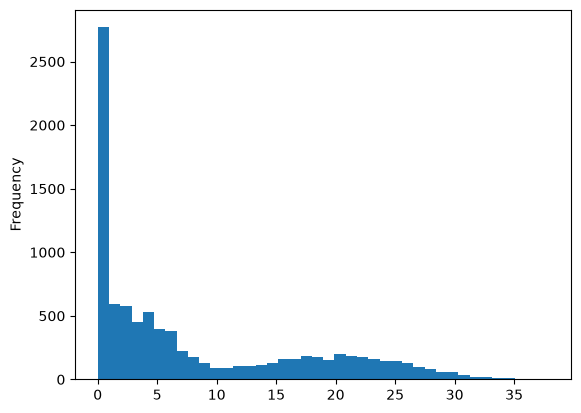

In [44]:
leads["minutos_web"].plot(kind="hist", bins=40) # Dibujo el histograma de los minutos en la web


**4.4** Haz lo mismo con otra columna de números.

Visitas de media: 3.4
Visitas de mediana: 3.0


<Axes: ylabel='Frequency'>

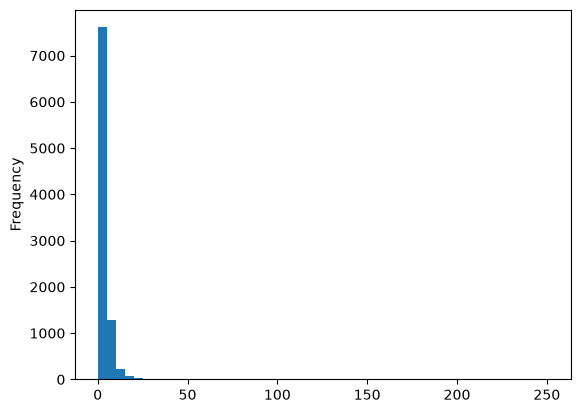

In [45]:
print("Visitas de media:", round(leads["visitas"].mean(), 1))
print("Visitas de mediana:", leads["visitas"].median())
leads["visitas"].plot(kind="hist", bins=50)       # Hago lo mismo con las visitas: media, mediana e histograma


Lo que he visto y lo que he decidido:

Lo que he visto y lo que he decidido:

He pasado el tiempo de segundos a minutos para que se entienda mejor. La mayoría pasa unos 4 minutos en la web y entra unas 3 veces. Hay mucha gente que no pasó nada de tiempo en la web (0 minutos) y alguien con 251 visitas, que es muy raro. Esto lo miro en el paso 5.

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

**5.3** Haz el diagrama de caja de esa columna.

**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

Lo que he visto y lo que he decidido:

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

**6.2** Dibújalo en barras.

Lo que he visto y lo que he decidido:

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

**7.2** Haz otra comparación con otra columna de grupos.

**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

Lo que he visto y lo que he decidido:

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

**8.2** Haz el gráfico de puntos de esas dos columnas.

Lo que he visto y lo que he decidido:

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos. Esto es lo que irá en el README y en la presentación.

Escribe aquí tus hallazgos.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.